# Numerai: Ridge и LightGBM

Локальное сравнение на **v5.3**, цель **target_ender_60**, набор **small (42 признака)**.
RFR не используется и не изменяется.

Обе модели обучены на одной выборке: до **200 строк из каждой обучающей эры**,
seed=42. Пропуски заполняются медианами только train; Ridge также стандартизирует
признаки. Оценка использует полные валидационные эры после промежутка в **13 недель**,
только строки validation с известной целью. Параметры заданы заранее, без подбора
и early stopping на validation.

Официальный `numerai_tools.scoring.numerai_corr` вычисляется по каждой эре.
Среднее даёт одинаковый вес эрам. CORR Sharpe не годовой; накопленный CORR и его
просадка не являются доходностью торгового портфеля.

[Данные](https://docs.numer.ai/numerai-tournament/data) ·
[CORR](https://docs.numer.ai/numerai-tournament/scoring/correlation-corr)

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'experiments' / 'numerai_baselines.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'experiments' / 'numerai_baselines.py').exists()
RESULTS = ROOT / 'experiments' / 'results' / 'numerai_baselines'
plt.rcParams['figure.figsize'] = (12, 4)


## Повторное обучение

Результаты уже сохранены, поэтому по умолчанию ноутбук только показывает их.
Для повторения выбери интерпретатор `.venv/Scripts/python.exe` и установи
`RUN_TRAINING = True`. Это перезапишет результаты.

Из корня проекта можно запустить:

```powershell
.\.venv\Scripts\python.exe experiments\numerai_baselines.py
```

In [2]:
RUN_TRAINING = False
if RUN_TRAINING:
    sys.path.insert(0, str(ROOT / 'experiments'))
    from numerai_baselines import run
    run(ROOT / 'downloads' / 'numerai' / 'v5.3', RESULTS)


In [3]:
config = json.loads((RESULTS / 'run_config.json').read_text(encoding='utf-8'))
summary = pd.read_csv(RESULTS / 'summary.csv', index_col='model')
scores = pd.read_csv(RESULTS / 'per_era_corr.csv', index_col='era')
periods = pd.read_csv(RESULTS / 'period_summary.csv')
display(pd.Series({
    'target': config['target'],
    'features': config['feature_count'],
    'train_rows': config['training']['rows'],
    'train_eras': config['training']['era_count'],
    'train_era_range': (config['training']['first_era'], config['training']['last_era']),
    'validation_rows': config['validation']['rows'],
    'validation_eras': config['validation']['era_count'],
    'validation_era_range': (config['validation']['first_era'], config['validation']['last_era']),
    'skipped_validation_rows': config['validation']['skipped'],
    'fit_seconds': config['fit_seconds'],
}))
display(summary.round(6))


target                                                       target_ender_60
features                                                                  42
train_rows                                                            114800
train_eras                                                               574
train_era_range                                                     (1, 574)
validation_rows                                                      4003128
validation_eras                                                          640
validation_era_range                                             (588, 1227)
skipped_validation_rows    {'gap_rows': 75468, 'non_validation_rows': 908...
fit_seconds                 {'Ridge': 0.6870000000053551, 'LightGBM': 12.25}
dtype: object

,eras,mean_corr,std_corr,corr_sharpe,positive_era_fraction,worst_era_corr,max_drawdown_cumulative_corr
model,,,,,,,
Ridge,640,0.012739,0.014339,0.888382,0.818750,-0.022942,0.109973
LightGBM,640,0.012025,0.014570,0.825292,0.782812,-0.035599,0.220092


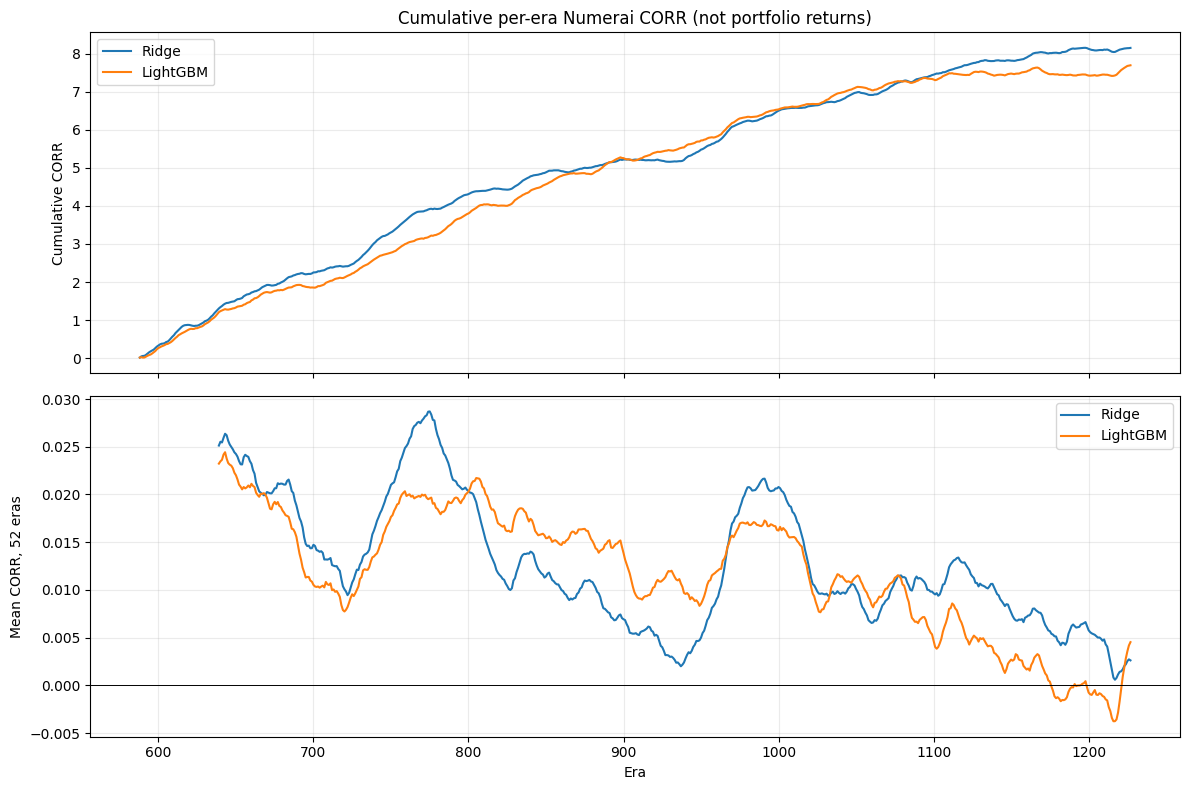

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
scores[['Ridge', 'LightGBM']].cumsum().plot(ax=axes[0])
axes[0].set_ylabel('Cumulative CORR')
axes[0].set_title('Cumulative per-era Numerai CORR (not portfolio returns)')
scores[['Ridge', 'LightGBM']].rolling(52, min_periods=52).mean().plot(ax=axes[1])
axes[1].axhline(0, color='black', linewidth=0.7)
axes[1].set_ylabel('Mean CORR, 52 eras')
axes[1].set_xlabel('Era')
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS / 'corr_over_time.png', dpi=150)
plt.show()


## Стабильность во времени

Две половины валидации показаны отдельно. Это описательная проверка, а не наборы
для настройки параметров. Соседние эры имеют перекрывающиеся целевые горизонты:
их нельзя считать независимыми для простых оценок статистической значимости.

,model,eras,mean_corr,std_corr,corr_sharpe,positive_era_fraction,worst_era_corr,max_drawdown_cumulative_corr,period
0,Ridge,320,0.016303,0.014829,1.099338,0.865625,-0.018219,0.052709,earlier_half
1,LightGBM,320,0.016226,0.013952,1.163002,0.853125,-0.024202,0.085814,earlier_half
2,Ridge,320,0.009175,0.012880,0.712296,0.771875,-0.022942,0.109973,later_half
3,LightGBM,320,0.007824,0.013951,0.560782,0.712500,-0.035599,0.220092,later_half


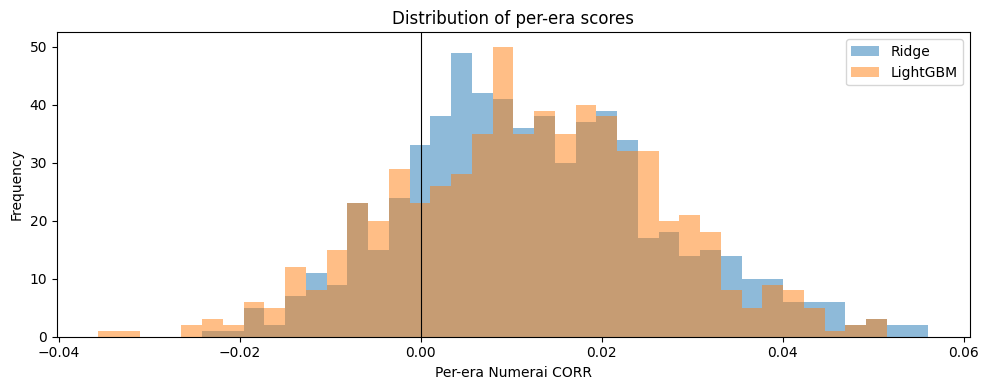

In [5]:
display(periods.round(6))
fig, ax = plt.subplots(figsize=(10, 4))
scores[['Ridge', 'LightGBM']].plot.hist(bins=40, alpha=0.5, ax=ax)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Per-era Numerai CORR')
ax.set_title('Distribution of per-era scores')
fig.tight_layout()
plt.show()


## Как читать результат

Это ориентир для работы над RFR, а не максимальное качество этих моделей:
использованы 42 признака и ограниченная обучающая выборка. Будущий RFR следует
сравнивать на тех же строках, признаках и эрах либо явно отмечать разницу объёмов.

Положительный средний CORR показывает исторический сигнал. Дополнительно смотрим
разброс, долю положительных эр и изменение качества во времени. Один прогон не
доказывает статистически надёжное превосходство. Если дальше подбирать параметры,
понадобятся отдельные периоды настройки и новая окончательная оценка.

Результаты: `experiments/results/numerai_baselines/`.
Модели и прогнозы: `downloads/numerai/baseline_artifacts/` (игнорируются Git).